# Fine-tuning Run 3: Detector and Crop Verifier

This run updates the detector with a new positive training source and then fine-tunes the crop verifier. The preflight cell reconstructs the dataset audit and exact-overlap filter used in the run. The other cells retain their recorded outputs.


## 01. Inputs, checkpoints, and training budget

Records the archive paths, starting weights, and time reserved for detector and verifier training.


In [1]:
# 1 | Paths, GPU budget and settings
from pathlib import Path, PurePosixPath
from collections import Counter
from datetime import datetime, timezone
import gc, hashlib, json, math, os, random, shutil, stat
import subprocess, sys, tarfile, tempfile, time, zipfile

if not Path("/kaggle/working").is_dir():
    raise RuntimeError("Open this notebook in Kaggle.")

LOCAL_INPUT_DIR = None  # Set e.g. "/kaggle/input/datasets/USER/fire-inputs" if Drive is blocked
# To reuse an output folder in the same session, set its full path here before running Cell 1.
EXISTING_RUN_DIR = None
TRAIN_ZIP = "fire_smoke_rpi5_10000fire_5000smoke_train_only.zip"
DRIVE_IDS = {
    TRAIN_ZIP: "1NVu0pa2z3yX6svDqJZoL9B3XgjrMKYV5",
    "detector_v4_kaggle.pt": "1DXe60BpmScvOpj_IsWgQvH55oYGt1mAw",
    "verifier.pt": "1LXl4TaTGuFNvpxDdxz_e5vPnZHP2zPHJ",
    "finetune_v4.tar": "1okdPs196qHFB4iluMfihUApFyiUomtPJ",
}
TRAIN_EXPECTED = {
    "fire_only": 5318,
    "fire_and_smoke": 4682,
    "smoke_only": 5000,
    "negative": 15186,
}
TRAIN_N = sum(TRAIN_EXPECTED.values())
EVAL_EXPECTED = {"val":3829, "hard_val":869}
NAMES = {0: "fire", 1: "smoke"}
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
BUDGET_HOURS = 8.5  # Set to actual remaining GPU time before starting if lower
YOLO_MAX_HOURS = 5.8
RESERVE_AFTER_YOLO_HOURS = 2.0
WRAP_UP_MINUTES = 15
YOLO_EPOCHS, YOLO_LR, IMGSZ, BATCH, WORKERS, DEVICE = 12, 1e-5, 800, 4, 2, 0
YOLO_LRF, YOLO_COS_LR = 0.50, True  # Decay toward YOLO_LR * YOLO_LRF over the planned run
YOLO_WARMUP_EPOCHS, YOLO_WARMUP_BIAS_LR = 0.0, 0.0
VERIFIER_EPOCHS, VERIFIER_BATCH = 6, 48
CROP_BATCH = 4
# A bounded, reproducible crop-mining scan. YOLO trains on the entire train-only ZIP.
MINE_TRAIN_POS, MINE_TRAIN_NEG = 5000, 5000
MIN_DET_CONF, VERIFIER_THRESHOLD = 0.20, 0.70  # Original pipeline settings
SEED, ULTRALYTICS_VERSION = 20261115, "8.4.194"

if "STARTED" not in globals():
    STARTED = time.monotonic()
def left_minutes():
    return (BUDGET_HOURS * 3600 - (time.monotonic() - STARTED)) / 60

WORKING = Path("/kaggle/working/final_fire_smoke")
WORKING.mkdir(exist_ok=True)
if EXISTING_RUN_DIR:
    RUN = Path(EXISTING_RUN_DIR).resolve()
    if not RUN.is_relative_to(WORKING) or RUN == WORKING or not RUN.is_dir():
        raise ValueError("EXISTING_RUN_DIR must be an existing run below " + str(WORKING))
else:
    RUN = WORKING / datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
    RUN.mkdir()
# Stay on the same local disk for downloads/extraction. Do not use mounted Drive for training I/O.
SCRATCH = Path("/tmp") / f"fire_smoke_final_{RUN.name}"
SCRATCH.mkdir(exist_ok=True)
NEW_DET = RUN / "detector_final_yolo.pt"
NEW_VER = RUN / "verifier_final.pt"
print("Outputs:", RUN)


Outputs: /kaggle/working/final_fire_smoke/20261115_102627_437619


## 02. Load the training environment and weights

Checks the GPU, locates the data archives and checkpoints, and initializes the verifier.


In [2]:
# 2 | Dependencies and downloads
import torch
if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU available. Enable GPU T4 x2 in Kaggle Settings.")
print("GPU:", torch.cuda.get_device_name(DEVICE), "| Torch:", torch.__version__, flush=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                f"ultralytics=={ULTRALYTICS_VERSION}", "gdown>=5,<7"], check=True)
import gdown
import cv2
import numpy as np
import torchvision
import ultralytics
import yaml
from ultralytics import YOLO
from tqdm.auto import tqdm
from IPython.display import display
import pandas as pd

if ultralytics.__version__ != ULTRALYTICS_VERSION:
    raise RuntimeError("Unexpected Ultralytics version. Restart the session before training.")
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

def get_file(name):
    valid = tarfile.is_tarfile if name.endswith(".tar") else zipfile.is_zipfile
    if LOCAL_INPUT_DIR:
        p = Path(LOCAL_INPUT_DIR) / name
        if not p.is_file():
            hits = sorted(q for q in Path(LOCAL_INPUT_DIR).rglob(name) if q.is_file())
            if len(hits) == 1:
                p = hits[0]
    else:
        p = SCRATCH / name
        if not p.is_file() or not valid(p):
            partial = p.with_suffix(p.suffix + ".partial")
            partial.unlink(missing_ok=True)
            try:
                print(f"Downloading {name} ...", flush=True)
                result = gdown.download(id=DRIVE_IDS[name], output=str(partial), quiet=False)
                if not result or not partial.is_file() or not valid(partial):
                    raise ValueError("Download did not produce the expected archive/checkpoint.")
                partial.replace(p)
            except Exception as exc:
                partial.unlink(missing_ok=True)
                raise RuntimeError(
                    f"Could not download {name}. Check Kaggle Internet and Drive link access, "
                    "or attach the files as a private Kaggle Dataset and set LOCAL_INPUT_DIR."
                ) from exc
    if not p.is_file() or not valid(p):
        raise ValueError(f"Missing or invalid archive/checkpoint: {p}")
    print(f"{name} ready ({p.stat().st_size / 1e6:,.0f} MB)")
    return p

archive = get_file(TRAIN_ZIP)
eval_archive = get_file("finetune_v4.tar")
base_det = get_file("detector_v4_kaggle.pt")
base_ver = get_file("verifier.pt")

def sha256_file(p):
    with Path(p).open("rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()

def atomic_copy(src, dst):
    tmp = dst.with_name(dst.name + ".partial")
    shutil.copy2(src, tmp)
    tmp.replace(dst)

def detector_for(p):
    m = YOLO(str(p), task="detect")
    raw = m.names
    labels = {int(i): str(v).strip().lower() for i, v in
              (raw.items() if isinstance(raw, dict) else enumerate(raw))}
    if m.task != "detect" or labels != NAMES:
        raise ValueError(f"{p}: unexpected task/class mapping, got {m.task} {labels}")
    return m

def release_gpu():
    gc.collect()
    torch.cuda.empty_cache()

# Match your deployed verifier's format and preserve its class index order.
verifier_seed = torch.load(base_ver, map_location="cpu", weights_only=True)
V_CLASSES = list(verifier_seed["classes"])
V_SIZE = int(verifier_seed.get("imgsz", 224))
V_PAD = float(verifier_seed.get("pad", .30))
if len(V_CLASSES) != 3 or set(V_CLASSES) != {"fire", "smoke", "not_fire"}:
    raise ValueError(f"Unexpected verifier classes: {V_CLASSES}")
if verifier_seed.get("arch", "efficientnet_b0") != "efficientnet_b0":
    raise ValueError("Expected EfficientNet-B0 verifier checkpoint.")

def make_verifier(ck):
    model = torchvision.models.efficientnet_b0(weights=None)
    model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, len(V_CLASSES))
    model.load_state_dict(ck["state_dict"], strict=True)
    return model

probe = detector_for(base_det)
del probe
probe = make_verifier(verifier_seed)
del probe
INPUT_HASHES = {"detector_sha256":sha256_file(base_det),"verifier_sha256":sha256_file(base_ver),
                "dataset_sha256":sha256_file(archive),"evaluation_sha256":sha256_file(eval_archive)}
print(f"Verifier loaded with classes {V_CLASSES}, crop size {V_SIZE}, pad {V_PAD}")


GPU: Tesla T4 | Torch: 2.11.0+cu130
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


Downloading...
From (original): https://drive.google.com/uc?id=1NVu0pa2z3yX6svDqJZoL9B3XgjrMKYV5
From (redirected): https://drive.google.com/uc?id=1NVu0pa2z3yX6svDqJZoL9B3XgjrMKYV5&confirm=t&uuid=3a6baa33-daf5-4d4b-8e8f-658762571641
To: /tmp/fire_smoke_final_20261115_102627_437619/fire_smoke_rpi5_10000fire_5000smoke_train_only.zip.partial
100%|██████████| 6.07G/6.07G [00:35<00:00, 172MB/s] 

fire_smoke_rpi5_10000fire_5000smoke_train_only.zip ready (6,067 MB)



Downloading...
From (original): https://drive.google.com/uc?id=1okdPs196qHFB4iluMfihUApFyiUomtPJ
From (redirected): https://drive.google.com/uc?id=1okdPs196qHFB4iluMfihUApFyiUomtPJ&confirm=t&uuid=aad03039-ae40-490a-9b0a-1793e7bd0b2b
To: /tmp/fire_smoke_final_20261115_102627_437619/finetune_v4.tar.partial
100%|██████████| 1.23G/1.23G [00:22<00:00, 54.3MB/s]

finetune_v4.tar ready (1,232 MB)



Downloading...
From (original): https://drive.google.com/uc?id=1DXe60BpmScvOpj_IsWgQvH55oYGt1mAw
From (redirected): https://drive.google.com/uc?id=1DXe60BpmScvOpj_IsWgQvH55oYGt1mAw&confirm=t&uuid=1ca14b8e-2a90-4189-b45f-43b842807273
To: /tmp/fire_smoke_final_20261115_102627_437619/detector_v4_kaggle.pt.partial
100%|██████████| 44.0M/44.0M [00:01<00:00, 38.0MB/s]

detector_v4_kaggle.pt ready (44 MB)



Downloading...
From: https://drive.google.com/uc?id=1LXl4TaTGuFNvpxDdxz_e5vPnZHP2zPHJ
To: /tmp/fire_smoke_final_20261115_102627_437619/verifier.pt.partial
100%|██████████| 16.3M/16.3M [00:00<00:00, 28.1MB/s]


verifier.pt ready (16 MB)
Verifier loaded with classes ['fire', 'not_fire', 'smoke'], crop size 224, pad 0.3


## 03. Audit training and validation data

Checks the train-only archive and removes exact train-image matches from the original validation list. Hard validation stays separate.


In [ ]:
# 3 | Audit the train-only archive and load separate validation splits
def unpack_zip(src, staging):
    with zipfile.ZipFile(src) as z:
        total, seen = 0, set()
        for m in z.infolist():
            q = PurePosixPath(m.filename)
            bits = (m.external_attr >> 16) & 0o170000
            if (not q.parts or q.is_absolute() or ".." in q.parts
                    or "\\" in m.filename or q in seen or bits not in (0, stat.S_IFDIR, stat.S_IFREG)):
                raise ValueError(f"Unsafe or duplicated ZIP member: {m.filename}")
            seen.add(q)
            total += m.file_size
        if shutil.disk_usage(staging).free < total + 2 * 2**30:
            raise RuntimeError("Not enough local space for dataset extraction plus crops.")
        z.extractall(staging)

extract = SCRATCH / "dataset"
mark = extract / ".archive-ok"
signature = INPUT_HASHES["dataset_sha256"]
if not mark.is_file() or mark.read_text() != signature:
    with tempfile.TemporaryDirectory(dir=SCRATCH) as tmp:
        stage = Path(tmp) / "unpack"
        stage.mkdir()
        unpack_zip(archive, stage)
        if extract.exists():
            shutil.rmtree(extract)
        stage.rename(extract)
        mark.write_text(signature)

DATA = extract.resolve()
for relative in ("data.yaml", "manifest.csv", "audit.json"):
    if not (DATA / relative).is_file():
        raise FileNotFoundError(f"Expected {relative} at the training ZIP root.")
for tree in ("images", "labels"):
    if not (DATA / tree / "train").is_dir():
        raise FileNotFoundError(f"Expected {tree}/train/ at the training ZIP root.")
    for split in ("val", "valid", "validation", "test"):
        if (DATA / tree / split).exists():
            raise ValueError(f"Expected a train-only ZIP, but found {tree}/{split}.")
source_yaml = yaml.safe_load((DATA / "data.yaml").read_text())
if not isinstance(source_yaml, dict) or not source_yaml.get("train"):
    raise ValueError("Training ZIP data.yaml must define train.")
if any(source_yaml.get(key) for key in ("val", "test")):
    raise ValueError("Training ZIP data.yaml must not reference a validation or test split.")
src_names = source_yaml.get("names")
if isinstance(src_names, list):
    src_names = dict(enumerate(src_names))
if not isinstance(src_names, dict) or {int(k):str(v).strip().lower() for k,v in src_names.items()} != NAMES:
    raise ValueError(f"Expected class IDs 0=fire, 1=smoke, got {src_names}")

def unpack_eval_tar(src, staging):
    # Extract only the two validation splits, not the old train or test splits.
    with tarfile.open(src, "r:*") as t:
        selected, seen = [], set()
        for m in t.getmembers():
            p = PurePosixPath(m.name)
            if not p.parts or p.parts[0] != "finetune_v4":
                continue
            if len(p.parts) == 2:
                wanted = p.name == "data.yaml"
            else:
                wanted = (len(p.parts) >= 3 and p.parts[1] in {"images","labels"}
                          and p.parts[2] in EVAL_EXPECTED)
            if not wanted:
                continue
            if p.is_absolute() or ".." in p.parts or p in seen or not (m.isreg() or m.isdir()):
                raise ValueError(f"Unsafe or duplicate evaluation member: {m.name}")
            selected.append(m)
            seen.add(p)
        if not selected:
            raise RuntimeError("No expected evaluation files found in finetune_v4.tar.")
        if shutil.disk_usage(staging).free < sum(m.size for m in selected) + 2*2**30:
            raise RuntimeError("Not enough scratch space for the previous evaluation images and crops.")
        t.extractall(path=staging,members=selected,filter="data")

old_extract = SCRATCH/"previous_eval"
old_mark = old_extract/".archive-ok"
old_signature = INPUT_HASHES["evaluation_sha256"]
if not old_mark.is_file() or old_mark.read_text() != old_signature:
    with tempfile.TemporaryDirectory(dir=SCRATCH) as tmp:
        stage = Path(tmp)/"unpack"
        stage.mkdir()
        unpack_eval_tar(eval_archive,stage)
        if old_extract.exists():
            shutil.rmtree(old_extract)
        stage.rename(old_extract)
        old_mark.write_text(old_signature)
OLD = old_extract/"finetune_v4"
old_names = yaml.safe_load((OLD/"data.yaml").read_text()).get("names")
if isinstance(old_names,list):
    old_names = dict(enumerate(old_names))
if not isinstance(old_names,dict) or {int(k):str(v).strip().lower() for k,v in old_names.items()} != NAMES:
    raise ValueError(f"Unexpected class IDs in the prior evaluation archive: {old_names}")

def label_for(root, img, split):
    return (root/"labels"/split/img.relative_to(root/"images"/split)).with_suffix(".txt")

def read_target(path):
    rows = []
    for line_number, line in enumerate(path.read_text(encoding="utf-8-sig").splitlines(), 1):
        if not line.strip():
            continue
        tokens = line.split()
        if len(tokens) != 5 or tokens[0] not in ("0", "1"):
            raise ValueError(f"Invalid detection label {path}:{line_number}")
        c, *v = (int(tokens[0]), *map(float, tokens[1:]))
        x,y,w,h = v
        if (not all(math.isfinite(a) and 0 <= a <= 1 for a in v) or min(w,h) <= 0
            or min(x-w/2,y-h/2) < -0.01 or max(x+w/2,y+h/2) > 1.01):
            raise ValueError(f"Out-of-range box {path}:{line_number}")
        rows.append((c,x,y,w,h))
    return rows

def image_list(root, split, n):
    paths = sorted(p for p in (root/"images"/split).rglob("*")
                   if p.is_file() and p.suffix.lower() in IMG_EXTS
                   and "__MACOSX" not in p.parts and not p.name.startswith("._"))
    if len(paths) != n:
        raise ValueError(f"{root.name}/{split}: expected {n:,} images, found {len(paths):,}")
    return paths

def class_counts(rows, counts):
    counts["positive" if rows else "negative"] += 1
    for c in {r[0] for r in rows}:
        counts[NAMES[c]+"_images"] += 1

def assert_both_classes(counts, name):
    if any(not counts[k] for k in ("positive","negative","fire_images","smoke_images")):
        raise RuntimeError(f"{name} must contain both detection classes and verified empty labels.")

SPLITS, LABELS, AUDIT = {"train":[]}, {}, {}
for sp,n in EVAL_EXPECTED.items():
    paths = image_list(OLD,sp,n)
    counts = Counter()
    for img in tqdm(paths,desc=f"Check old {sp} labels",mininterval=4):
        targets = read_target(label_for(OLD,img,sp))
        LABELS[img] = targets
        class_counts(targets,counts)
    assert_both_classes(counts,sp)
    SPLITS[sp] = paths
    AUDIT[sp] = {"source":"previous evaluation archive","images":len(paths),"label_counts":dict(counts)}

train_paths = image_list(DATA, "train", TRAIN_N)
train_counts = Counter()
categories = {(0,): "fire_only", (0, 1): "fire_and_smoke", (1,): "smoke_only", (): "negative"}
expected_label_paths = {label_for(DATA, p, "train") for p in train_paths}
found_label_paths = {p for p in (DATA / "labels" / "train").rglob("*.txt")
                     if p.is_file() and "__MACOSX" not in p.parts and not p.name.startswith("._")}
if len(expected_label_paths) != TRAIN_N or found_label_paths != expected_label_paths:
    raise ValueError("Expected one matching label per training image and no orphan labels. "
                     f"Missing: {len(expected_label_paths - found_label_paths)}, "
                     f"extra: {len(found_label_paths - expected_label_paths)}, "
                     f"unique expected labels: {len(expected_label_paths)}.")
for img in tqdm(train_paths, desc="Check new training labels", mininterval=4):
    targets = read_target(label_for(DATA, img, "train"))
    LABELS[img] = targets
    train_counts[categories[tuple(sorted({row[0] for row in targets}))]] += 1
if dict(train_counts) != TRAIN_EXPECTED:
    raise ValueError(f"Training categories do not match. Found {dict(train_counts)}, expected {TRAIN_EXPECTED}.")

SPLITS["train"] = train_paths
AUDIT["train"] = {
    "source": archive.name,
    "images": len(train_paths),
    "labels": len(expected_label_paths),
    "categories": dict(train_counts),
    "fire_images": train_counts["fire_only"] + train_counts["fire_and_smoke"],
    "smoke_images": train_counts["smoke_only"] + train_counts["fire_and_smoke"],
}
# Read-only guard. Keep all training images and both external evaluation splits unchanged.
# Index evaluation first so overlaps can be reported by split without retaining all training hashes.
eval_hashes = {}
for sp in EVAL_EXPECTED:
    for p in tqdm(SPLITS[sp], desc=f"Hash external {sp}", mininterval=4):
        eval_hashes.setdefault(sha256_file(p), []).append((sp, p))
overlap_counts, examples = Counter(), []
for p in tqdm(train_paths, desc="Check train vs external evaluation", mininterval=4):
    for sp, vp in eval_hashes.get(sha256_file(p), ()):
        overlap_counts[sp] += 1
        if len(examples) < 20:
            examples.append({"train":str(p.relative_to(DATA)), "split":sp,
                             "evaluation":str(vp.relative_to(OLD))})
AUDIT["exact_cross_split_overlap"] = {
    "image_pairs": {sp:overlap_counts[sp] for sp in EVAL_EXPECTED},
    "examples": examples,
}
(RUN / "dataset_audit.json").write_text(json.dumps(AUDIT, indent=2))
if overlap_counts["hard_val"]:
    raise ValueError("Found overlap in hard_val. Use a clean hard-validation split.")

if overlap_counts["val"]:
    exclude_from_val = set()
    for p in tqdm(train_paths, desc="Find matching validation images"):
        for split, val_path in eval_hashes.get(sha256_file(p), ()):
            if split == "val":
                exclude_from_val.add(val_path)

    SPLITS["val"] = [p for p in SPLITS["val"] if p not in exclude_from_val]

    counts = Counter()
    for p in SPLITS["val"]:
        class_counts(LABELS[p], counts)
    assert_both_classes(counts, "filtered external val")

    AUDIT["val"].update(
        images=len(SPLITS["val"]),
        label_counts=dict(counts),
        excluded_exact_train_matches=len(exclude_from_val),
    )
    (RUN / "dataset_audit.json").write_text(json.dumps(AUDIT, indent=2))

    print(f"Excluded {len(exclude_from_val)} images from the validation list only.")
    print(f"Training: {len(SPLITS['train']):,} | Validation: {len(SPLITS['val']):,}")

for sp, paths in SPLITS.items():
    (SCRATCH/f"{sp}.txt").write_text("\n".join(str(p) for p in paths)+"\n")
DATA_YAML = SCRATCH / "data_kaggle.yaml"
DATA_YAML.write_text(yaml.safe_dump({
    "path":str(DATA), "train":str(SCRATCH/"train.txt"), "val":str(SCRATCH/"val.txt"), "names":NAMES,
}, sort_keys=False))
print("Training:", AUDIT["train"])
print("Exact train/evaluation matches before filtering:", AUDIT["exact_cross_split_overlap"]["image_pairs"])
print("Kaggle YOLO data.yaml:", DATA_YAML)
print("Old val:", AUDIT["val"], "| old hard_val:", AUDIT["hard_val"])
print(f"Ready. GPU budget remaining by this notebook's timer: {left_minutes():.1f} minutes.")


## 04. Inspect training annotations

Shows fire-only, smoke-only, mixed, and background samples with their training labels.


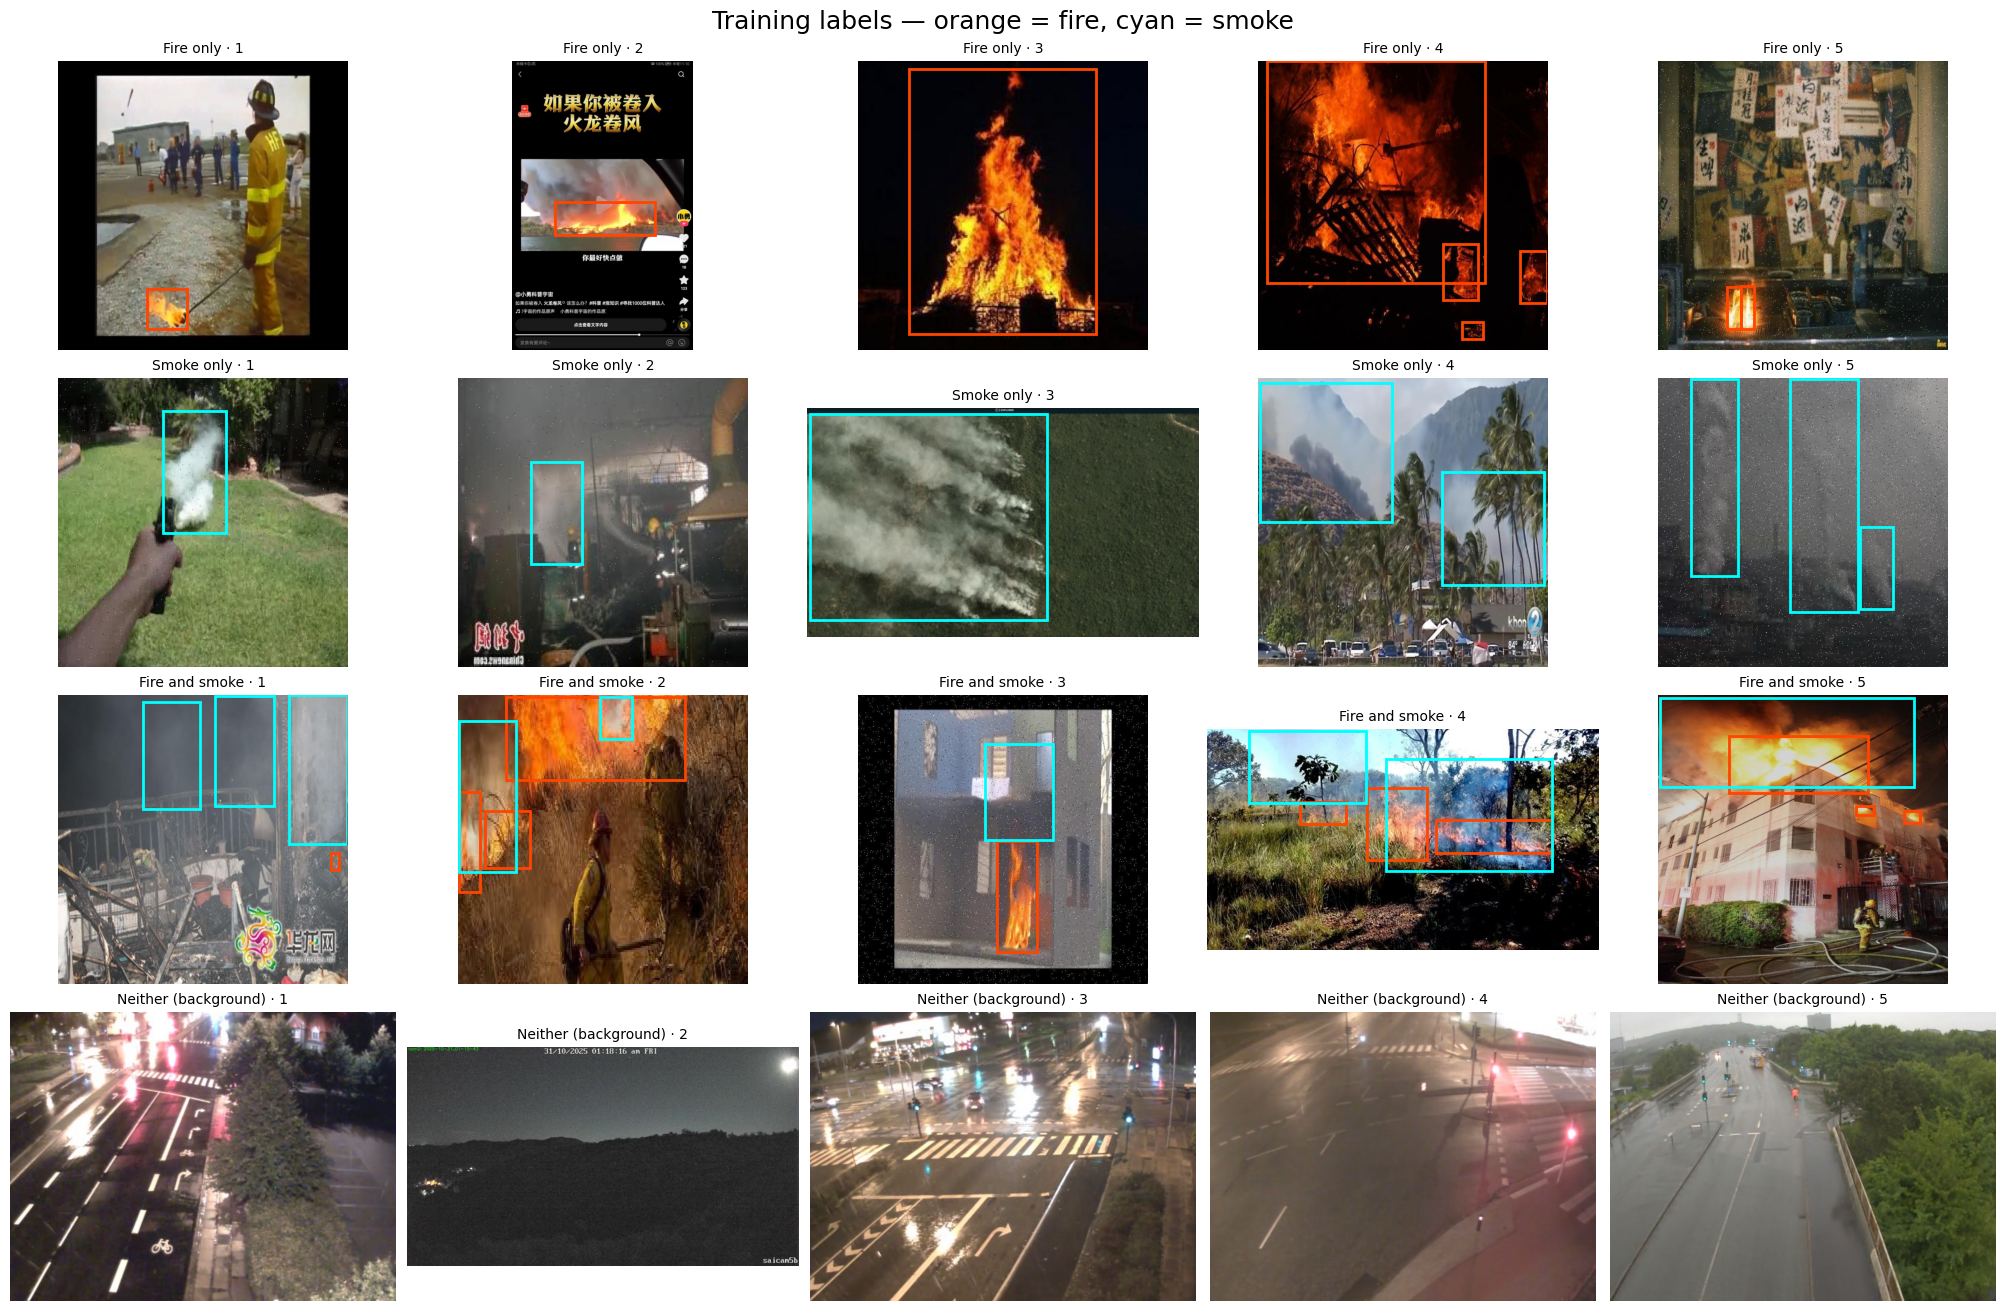

In [6]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps

categories = {
    (0,): "Fire only",
    (1,): "Smoke only",
    (0, 1): "Fire and smoke",
    (): "Neither (background)",
}
groups = {key: [] for key in categories}
colors = {0: "orangered", 1: "cyan"}
class_names = {0: "fire", 1: "smoke"}

for path in SPLITS["train"]:
    classes = tuple(sorted({row[0] for row in LABELS[path]}))
    groups[classes].append(path)

rng = random.Random()  # Rerun the cell to see a new sample
fig, axes = plt.subplots(4, 5, figsize=(20, 13), layout="constrained")
fig.suptitle("Training labels — orange = fire, cyan = smoke", fontsize=18)

for row, (classes, category) in enumerate(categories.items()):
    for col, path in enumerate(rng.sample(groups[classes], 5)):
        ax = axes[row, col]
        with Image.open(path) as source:
            img = ImageOps.exif_transpose(source).convert("RGB")
            img.thumbnail((640, 640))
        w, h = img.size
        ax.imshow(img, extent=(0, w, h, 0))

        for cls, cx, cy, bw, bh in LABELS[path]:
            x, y = (cx - bw / 2) * w, (cy - bh / 2) * h
            ax.add_patch(Rectangle(
                (x, y), bw * w, bh * h,
                fill=False, edgecolor=colors[cls], linewidth=2
            ))

        ax.set_title(f"{category} · {col + 1}", fontsize=10)
        ax.axis("off")

plt.show()
plt.close(fig)

## 05. Record the training schedule

Saves detector and verifier settings and estimates the time available for detector training.


In [7]:
# 4 | Budget planning helpers
def yolo_window():
    # Bound this training phase; save and exit normally at an epoch boundary.
    return min(YOLO_MAX_HOURS*60, left_minutes()-RESERVE_AFTER_YOLO_HOURS*60)

def train_setting_record():
    return {
        **INPUT_HASHES, "dataset_archive": archive.name, "gpu": torch.cuda.get_device_name(DEVICE),
        "ultralytics":ultralytics.__version__, "imgs":IMGSZ, "detector_batch":BATCH,
        "planned_detector_epochs":YOLO_EPOCHS, "planned_verifier_epochs":VERIFIER_EPOCHS,
        "detector_lr0":YOLO_LR, "detector_lrf":YOLO_LRF, "detector_cos_lr":YOLO_COS_LR,
        "detector_warmup_epochs":YOLO_WARMUP_EPOCHS, "detector_warmup_bias_lr":YOLO_WARMUP_BIAS_LR,
        "verifier_threshold":VERIFIER_THRESHOLD, "budget_hours":BUDGET_HOURS,
        "train_images":len(SPLITS["train"]), "validation_images":len(SPLITS["val"]),
    }
(RUN/"settings.json").write_text(json.dumps(train_setting_record(),indent=2))
prior_epoch_min = 10.667 * len(SPLITS["train"])/12258 + 1 * len(SPLITS["val"])/3829
print(f"Historical estimate: {prior_epoch_min:.1f} minutes/YOLO epoch including validation.")
print(f"YOLO phase allowance: {yolo_window():.1f} min, leaving time for verifier and reports.")


Historical estimate: 27.3 minutes/YOLO epoch including validation.
YOLO phase allowance: 348.0 min, leaving time for verifier and reports.


## 06. Fine-tune the detector

Starts from the selected checkpoint in run 2 and saves the detector checkpoints and epoch metrics.


In [8]:
# 5 | Fine-tune YOLO from Kaggle's best weights and export the new best
# One GPU, new optimizer, same image size and batch as the previous Kaggle run.
def train_detector():
    cap = yolo_window()
    if cap < 30:
        raise RuntimeError("Less than 30 minutes for YOLO after reserving verifier time. Check your remaining quota.")
    window_started = time.monotonic()
    last_epoch_t = None
    dt = []

    def epoch_checkpoint(trainer):
        nonlocal last_epoch_t
        now = time.monotonic()
        dt.append((now - (last_epoch_t if last_epoch_t is not None else window_started)) / 60)
        last_epoch_t = now
        elapsed = (now-window_started)/60
        estimate = max(1, sum(dt[-3:])/len(dt[-3:]))*1.12
        allowed = min(cap-elapsed, left_minutes()-RESERVE_AFTER_YOLO_HOURS*60)
        print(f"YOLO {trainer.epoch+1}/{YOLO_EPOCHS} | phase {elapsed:.1f} min | "
              f"next epoch estimate {estimate:.1f} min | total left {left_minutes():.1f} min", flush=True)
        if allowed < estimate and trainer.epoch+1 < YOLO_EPOCHS:
            print("Stopping YOLO after this completed epoch to reserve the verifier budget.", flush=True)
            trainer.stop = True

    m = detector_for(base_det)
    m.add_callback("on_fit_epoch_end", epoch_checkpoint)
    m.train(
        data=str(DATA_YAML), resume=False, epochs=YOLO_EPOCHS, time=None, patience=0,
        imgsz=IMGSZ, batch=BATCH, workers=WORKERS, device=DEVICE,
        optimizer="AdamW", lr0=YOLO_LR, lrf=YOLO_LRF, cos_lr=YOLO_COS_LR,
        warmup_epochs=YOLO_WARMUP_EPOCHS, warmup_bias_lr=YOLO_WARMUP_BIAS_LR,
        hsv_h=.005, hsv_s=.50, hsv_v=.30, degrees=0., translate=.08, scale=.35,
        fliplr=.5, mosaic=.25, mixup=0., close_mosaic=2,
        amp=True, cache=False, val=True, seed=SEED, deterministic=False,
        save=True, save_period=-1, plots=True, fraction=1., project=str(RUN),
        name="yolo", exist_ok=False,
    )
    yolo_path = Path(m.trainer.save_dir)
    best = yolo_path / "weights" / "best.pt"
    if not best.is_file():
        raise FileNotFoundError(best)
    atomic_copy(best, NEW_DET)
    atomic_copy(yolo_path/"results.csv", RUN/"yolo_results.csv")
    print(f"YOLO candidate saved: {NEW_DET}", flush=True)
    del m
    release_gpu()

if not NEW_DET.is_file():
    if (RUN/"yolo"/"weights"/"best.pt").exists():
        raise RuntimeError("An interrupted YOLO run exists. See the notebook's recovery notes before rerunning.")
    train_detector()
else:
    print("Keeping the completed YOLO candidate:", NEW_DET)


New https://pypi.org/project/ultralytics/8.4.213 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/tmp/fire_smoke_final_20261115_102627_437619/data_kaggle.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.005, hsv_s=0.5, hsv_v=0.3, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=1e-05, lrf=0.5, mask_ratio=4, max_det=300, mixup=0.0, mode=tr

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/12      7.26G       1.39      1.342    0.01668          2        800: 100% ━━━━━━━━━━━━ 7547/7547 4.5it/s 28:070.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 471/471 7.6it/s 1:020.1sss
                   all       3764       5133      0.738      0.638      0.723      0.459
YOLO 2/12 | phase 59.0 min | next epoch estimate 33.0 min | total left 442.9 min

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/12      7.26G      1.375      1.332    0.01665          0        800: 100% ━━━━━━━━━━━━ 7547/7547 4.5it/s 28:090.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 471/471 7.6it/s 1:020.2sss
                   all       3764       5133      0.729      0.637      0.718      0.454
YOLO 3/12 | phase 88.2 min | next epoch estimate 32.9 min | total left 413.7 min

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  I

## 07. Select the last completed detector epoch

Copies the last detector checkpoint to a separate run folder for verifier training and evaluation. The recorded run uses epoch 11.


In [10]:
last_yolo = RUN / "yolo" / "weights" / "last.pt"
assert last_yolo.is_file(), f"Checkpoint not found: {last_yolo}"

# Keep the best checkpoint and its verifier outputs separate.
RUN = RUN / "last_epoch_verifier"
RUN.mkdir(exist_ok=True)

NEW_DET = RUN / "detector_last_epoch.pt"
NEW_VER = RUN / "verifier_final.pt"
atomic_copy(last_yolo, NEW_DET)

print("Using last YOLO checkpoint:", NEW_DET)

Using last YOLO checkpoint: /kaggle/working/final_fire_smoke/20261115_102627_437619/last_epoch_verifier/detector_last_epoch.pt


## 08. Build the verifier crop dataset

Combines detector proposals and ground-truth crops and mines background examples for verifier training.


In [12]:
# 6 | Build verifier crops using the selected YOLO checkpoint
MINE_TRAIN_NEG = 10_000
TRAIN_CROP_CONF = 0.02


def square_crop(img, box, pad=0.3, min_side=16):
    h, w = img.shape[:2]
    x1, y1, x2, y2 = map(float, box)
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    half = max(max(x2 - x1, y2 - y1, 1.0) * (1 + 2 * pad), min_side) / 2
    a, b = math.floor(cx - half), math.floor(cy - half)
    c, d = math.ceil(cx + half), math.ceil(cy + half)
    pl, pt, pr, pb = max(0, -a), max(0, -b), max(0, c - w), max(0, d - h)
    crop = img[max(0, b):min(h, d), max(0, a):min(w, c)]
    if crop.size == 0:
        return None
    if pl or pt or pr or pb:
        crop = cv2.copyMakeBorder(crop, pt, pb, pl, pr, cv2.BORDER_REPLICATE)
    return crop


def box_iou(a, b):
    a = np.asarray(a, dtype=np.float32).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float32).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=np.float32)

    ix1 = np.maximum(a[:, None, 0], b[None, :, 0])
    iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2])
    iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.clip(area_a[:, None] + area_b[None, :] - inter, 1e-9, None)


def pixel_targets(img, w, h):
    classes, coords = [], []
    for c, x, y, bw, bh in LABELS[img]:
        classes.append(c)
        coords.append((
            max(0., (x - bw / 2) * w), max(0., (y - bh / 2) * h),
            min(w, (x + bw / 2) * w), min(h, (y + bh / 2) * h),
        ))
    return classes, np.asarray(coords, dtype=np.float32).reshape(-1, 4)


def selected_mining_train():
    rng = random.Random(SEED)
    positives = [p for p in SPLITS["train"] if LABELS[p]]
    negatives = [p for p in SPLITS["train"] if not LABELS[p]]

    pos = rng.sample(positives, min(MINE_TRAIN_POS, len(positives)))
    neg = rng.sample(negatives, min(MINE_TRAIN_NEG, len(negatives)))

    # Keep batches homogeneous so only background batches use the lower cutoff.
    batches = [
        pool[i:i + CROP_BATCH]
        for pool in (pos, neg)
        for i in range(0, len(pool), CROP_BATCH)
    ]
    # Put incomplete batches last to keep the other batches aligned.
    full = [batch for batch in batches if len(batch) == CROP_BATCH]
    partial = [batch for batch in batches if len(batch) < CROP_BATCH]
    rng.shuffle(full)
    return [p for batch in full + partial for p in batch]


def infer_groups(model, paths, desc, conf=None, mine_background=False):
    if conf is None:
        conf = MIN_DET_CONF

    iterator = range(0, len(paths), CROP_BATCH)
    for i in tqdm(iterator, desc=desc, mininterval=5):
        group = paths[i:i + CROP_BATCH]
        imgs = [cv2.imread(str(p), cv2.IMREAD_COLOR) for p in group]
        if any(im is None for im in imgs):
            bad = [str(p) for p, im in zip(group, imgs) if im is None]
            raise ValueError(f"Cannot decode: {bad[:3]}")

        if mine_background:
            # Handle mixed batches too, including a partial batch at the end.
            indices = [
                ([j for j, p in enumerate(group) if LABELS[p]], conf),
                ([j for j, p in enumerate(group) if not LABELS[p]], TRAIN_CROP_CONF),
            ]
        else:
            indices = [(list(range(len(group))), conf)]

        preds = [None] * len(group)
        for idx, cutoff in indices:
            if not idx:
                continue
            results = model.predict(
                [imgs[j] for j in idx],
                imgsz=IMGSZ, conf=cutoff, iou=.50, max_det=50,
                device=DEVICE, verbose=False, save=False, rect=False,
            )
            if len(results) != len(idx):
                raise RuntimeError("Detector returned the wrong number of predictions.")
            for j, result in zip(idx, results):
                preds[j] = result

        yield zip(group, imgs, preds)


def pred_boxes(result):
    if result.boxes is None or not len(result.boxes):
        return []
    b = result.boxes
    classes = b.cls.cpu().tolist()
    scores = b.conf.cpu().tolist()
    xyxy = b.xyxy.cpu().numpy()
    return sorted(
        [(int(c), float(s), box) for c, s, box in zip(classes, scores, xyxy)
         if box[2] - box[0] >= 4 and box[3] - box[1] >= 4],
        key=lambda item: -item[1],
    )


def match_stats(classes, gt, predictions):
    counts = Counter()
    for c in classes:
        counts[NAMES[c] + "_total"] += 1

    if not classes:
        counts["negative_images"] = 1
        counts["negative_images_flagged"] = int(bool(predictions))
        counts["false_boxes_on_negative_images"] = len(predictions)
        return counts

    matched = set()
    overlap = box_iou([box for _, _, box in predictions], gt)
    for j, (c, _, _) in enumerate(predictions):
        options = [
            k for k, gc in enumerate(classes)
            if gc == c and k not in matched and overlap[j, k] >= .5
        ]
        if options:
            k = max(options, key=lambda k: overlap[j, k])
            matched.add(k)
            counts[NAMES[c] + "_hits"] += 1
    return counts


def create_crops(model, paths, split, folder, crop_deadline):
    counters, val_stats, n_seen = Counter(), Counter(), 0
    is_train = split == "train"
    source_root = DATA if is_train else OLD

    with (folder / f"{split}_crops.jsonl").open("w") as manifest:
        for group in infer_groups(
            model, paths, f"{split} crop mining", mine_background=is_train
        ):
            for img, frame, result in group:
                n_seen += 1
                h, w = frame.shape[:2]
                cls, gt = pixel_targets(img, w, h)
                pred = pred_boxes(result)
                selected, per_image = [], Counter()
                overlaps = box_iou([b for _, _, b in pred], gt)

                if not is_train:
                    val_stats.update(match_stats(cls, gt, pred))

                for i, (_, score, box) in enumerate(pred):
                    if not cls:
                        label = "not_fire"
                        cap = 4 if is_train else len(pred)
                    else:
                        k = int(overlaps[i].argmax())
                        if overlaps[i, k] < .50:
                            continue
                        label = NAMES[cls[k]]
                        cap = 3 if is_train else len(pred)

                    if per_image[label] >= cap:
                        continue
                    if is_train and any(
                        l == label and box_iou([box], [b])[0, 0] >= .85
                        for l, b, _, _ in selected
                    ):
                        continue
                    selected.append((label, box, "prediction", score))
                    per_image[label] += 1

                if is_train:
                    for c, box in zip(cls, gt):
                        label = NAMES[c]
                        if per_image[label] >= 2:
                            continue
                        if any(
                            l == label and box_iou([box], [b])[0, 0] >= .70
                            for l, b, _, _ in selected
                        ):
                            continue
                        selected.append((label, box, "ground_truth", None))
                        per_image[label] += 1

                for j, (label, box, kind, confidence) in enumerate(selected):
                    crop = square_crop(frame, box, pad=V_PAD)
                    if crop is None:
                        continue
                    resized = cv2.resize(
                        crop, (V_SIZE, V_SIZE),
                        interpolation=cv2.INTER_AREA if crop.shape[0] > V_SIZE
                        else cv2.INTER_LINEAR,
                    )
                    dest = folder / split / label / f"{n_seen:06d}_{j:02d}.png"
                    if not cv2.imwrite(
                        str(dest), resized, [cv2.IMWRITE_PNG_COMPRESSION, 1]
                    ):
                        raise OSError(f"Failed writing crop: {dest}")

                    counters[label] += 1
                    counters[f"{label}_{kind}"] += 1
                    manifest.write(json.dumps({
                        "file": str(dest.relative_to(folder)),
                        "source": str(img.relative_to(source_root)),
                        "kind": kind,
                        "conf": confidence,
                        "bbox": [float(v) for v in box],
                    }) + "\n")

            if time.monotonic() >= crop_deadline:
                break

    return dict(counters), dict(val_stats), n_seen


def run_crop_stage():
    available = left_minutes() - 55
    if available < 10:
        raise RuntimeError("Less than 10 minutes for crop mining after reserving verifier time.")
    deadline = time.monotonic() + 60 * min(65, available)

    if shutil.disk_usage(SCRATCH).free < 2 * 2**30:
        raise RuntimeError("Less than 2 GiB of local disk space for verifier crops.")

    with tempfile.TemporaryDirectory(dir=SCRATCH) as tmp:
        staged = Path(tmp) / "crops"
        for split in ("train", "val"):
            for label in V_CLASSES:
                (staged / split / label).mkdir(parents=True, exist_ok=True)

        model = detector_for(NEW_DET)
        try:
            val_counts, det_stats, val_seen = create_crops(
                model, SPLITS["val"], "val", staged, deadline
            )
            if val_seen != len(SPLITS["val"]):
                raise RuntimeError("Budget ended before validation crop mining finished.")
            if time.monotonic() >= deadline:
                raise RuntimeError("Crop budget ended after validation.")

            train_paths = selected_mining_train()
            train_counts, _, train_seen = create_crops(
                model, train_paths, "train", staged, deadline
            )
        finally:
            del model
            release_gpu()

        print("Training crop counts:", train_counts)
        print("Validation crop counts:", val_counts)
        if train_seen < len(train_paths):
            print(f"Crop time cap reached. Scanned {train_seen:,}/{len(train_paths):,} training images.")

        for label in V_CLASSES:
            if train_counts.get(label, 0) < 30 or val_counts.get(label, 0) < 5:
                raise RuntimeError(
                    f"Too few {label} crops: train={train_counts.get(label, 0)}, "
                    f"val={val_counts.get(label, 0)}. YOLO weights are unchanged."
                )

        record = {
            "train": train_counts,
            "validation": val_counts,
            "train_scanned": train_seen,
            "val_scanned": val_seen,
            "train_requested": len(train_paths),
            "val_yolo_counts": det_stats,
            "crop_manifest_sha256": {
                split: sha256_file(staged / f"{split}_crops.jsonl")
                for split in ("train", "val")
            },
        }
        (staged / "ready.json").write_text(json.dumps(record, indent=2))
        if CROP_ROOT.exists():
            shutil.rmtree(CROP_ROOT)
        staged.rename(CROP_ROOT)

    return record


CROP_ROOT = SCRATCH / "verifier_crops"
if not NEW_DET.is_file():
    raise FileNotFoundError(f"Selected YOLO checkpoint not found: {NEW_DET}")

print("Mining crops with:", NEW_DET, flush=True)
fingerprint = {
    "detector": sha256_file(NEW_DET),
    "verifier": INPUT_HASHES["verifier_sha256"],
    "dataset": signature,
    "old_evaluation": old_signature,
    "val_list": sha256_file(SCRATCH / "val.txt"),
    "conf": MIN_DET_CONF,
    "train_crop_conf": TRAIN_CROP_CONF,
    "imgsz": IMGSZ,
    "seed": SEED,
    "mine_pos": MINE_TRAIN_POS,
    "mine_neg": MINE_TRAIN_NEG,
}
stamp = CROP_ROOT / "inputs.json"
if (
    (CROP_ROOT / "ready.json").is_file()
    and stamp.is_file()
    and json.loads(stamp.read_text()) == fingerprint
):
    records = json.loads((CROP_ROOT / "ready.json").read_text())
else:
    records = run_crop_stage()
    stamp.write_text(json.dumps(fingerprint))

(RUN / "crop_audit.json").write_text(json.dumps(records, indent=2))
print(json.dumps(records, indent=2))
print(f"{left_minutes():.1f} minutes left on the notebook timer.")

Mining crops with: /kaggle/working/final_fire_smoke/20261115_102627_437619/last_epoch_verifier/detector_last_epoch.pt


val crop mining:   0%|          | 0/941 [00:00<?, ?it/s]

train crop mining:   0%|          | 0/3750 [00:00<?, ?it/s]

Training crop counts: {'smoke': 4425, 'smoke_prediction': 2761, 'fire': 5474, 'fire_ground_truth': 1178, 'fire_prediction': 4296, 'not_fire': 284, 'not_fire_prediction': 284, 'smoke_ground_truth': 1664}
Validation crop counts: {'not_fire': 194, 'not_fire_prediction': 194, 'smoke': 1375, 'smoke_prediction': 1375, 'fire': 1818, 'fire_prediction': 1818}
{
  "train": {
    "smoke": 4425,
    "smoke_prediction": 2761,
    "fire": 5474,
    "fire_ground_truth": 1178,
    "fire_prediction": 4296,
    "not_fire": 284,
    "not_fire_prediction": 284,
    "smoke_ground_truth": 1664
  },
  "validation": {
    "not_fire": 194,
    "not_fire_prediction": 194,
    "smoke": 1375,
    "smoke_prediction": 1375,
    "fire": 1818,
    "fire_prediction": 1818
  },
  "train_scanned": 15000,
  "val_scanned": 3764,
  "train_requested": 15000,
  "val_yolo_counts": {
    "negative_images": 1615,
    "negative_images_flagged": 141,
    "false_boxes_on_negative_images": 194,
    "smoke_total": 2071,
    "smoke_h

## 09. Fine-tune EfficientNet-B0

Keeps the detector fixed, updates the crop verifier, and records validation scores across verifier epochs.


In [13]:
# 7 | Fine-tune EfficientNet-B0 from verifier.pt, keeping YOLO fixed
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

V_DEVICE = torch.device(f"cuda:{DEVICE}")
V_INDEX = {label:i for i,label in enumerate(V_CLASSES)}
EV_IDX = [V_INDEX["fire"],V_INDEX["smoke"]]
NORM = T.Normalize([.485,.456,.406],[.229,.224,.225])
train_transform = T.Compose([T.ToPILImage(),T.RandomHorizontalFlip(),
    T.RandomApply([T.ColorJitter(.12,.12,.12,.01)],p=.4),T.ToTensor(),NORM])
eval_transform = T.Compose([T.ToTensor(),NORM])

class CropDataset(Dataset):
    def __init__(self, split, transform):
        self.items = [(p,V_INDEX[c]) for c in V_CLASSES
                      for p in sorted((CROP_ROOT/split/c).glob("*.png"))]
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        p,y = self.items[i]
        bgr = cv2.imread(str(p),cv2.IMREAD_COLOR)
        if bgr is None:
            raise ValueError(f"Cannot read crop: {p}")
        return self.transform(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)),y

def make_loader(split,batch):
    dataset = CropDataset(split,train_transform if split=="train" else eval_transform)
    return DataLoader(dataset,batch_size=batch,shuffle=split=="train",
                      num_workers=WORKERS,pin_memory=True,persistent_workers=WORKERS>0)

def verifier_metrics(net,loader):
    net.eval()
    targets, passed = [], []
    with torch.inference_mode():
        for x,y in tqdm(loader,desc="verifier validation",leave=False,mininterval=4):
            scores = net(x.to(V_DEVICE,non_blocking=True)).float().softmax(1)
            targets.append(y.numpy())
            passed.append((scores[:,EV_IDX].sum(1) >= VERIFIER_THRESHOLD).cpu().numpy())
    y = np.concatenate(targets)
    keep = np.concatenate(passed)
    counts = {c:int((y==i).sum()) for c,i in V_INDEX.items()}
    if not all(counts.values()):
        raise RuntimeError("Validation crops missing at least one class.")
    return {"fire_kept":float(keep[y==V_INDEX["fire"]].mean()),
            "smoke_kept":float(keep[y==V_INDEX["smoke"]].mean()),
            "negative_rejected":float((~keep[y==V_INDEX["not_fire"]]).mean()),
            "counts":counts}

def verifier_rank(row, baseline):
    # Prefer candidates that preserve both classes within 2 percentage points
    # of the old verifier, then maximize rejection. This is selection, not a deployment claim.
    excess = max(0.,baseline["fire_kept"] - row["fire_kept"] - .02,
                 baseline["smoke_kept"] - row["smoke_kept"] - .02)
    safe = excess < 1e-9
    return (int(safe),-excess,row["negative_rejected"],min(row["fire_kept"],row["smoke_kept"]))

def safe_torch_save(item,path):
    temp = path.with_name(path.name+".partial")
    torch.save(item,temp)
    temp.replace(path)

def train_verifier():
    if not (CROP_ROOT/"ready.json").is_file():
        raise RuntimeError("Finish Cell 6 first.")
    dl_train,dl_val = make_loader("train",VERIFIER_BATCH),make_loader("val",VERIFIER_BATCH)
    net = make_verifier(verifier_seed).to(V_DEVICE)
    weight = Counter(y for _,y in dl_train.dataset.items)
    class_weights = torch.tensor([len(dl_train.dataset)/(len(V_CLASSES)*weight[i])
                                  for i in range(len(V_CLASSES))],dtype=torch.float32,device=V_DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights,label_smoothing=.02)
    opt = torch.optim.AdamW([
        {"params":net.features.parameters(),"lr":3e-5},
        {"params":net.classifier.parameters(),"lr":1e-4},
    ],weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=VERIFIER_EPOCHS)
    scaler = torch.amp.GradScaler("cuda")
    last = RUN/"verifier_last_training.pt"
    history,best_rank = [],None
    resume_key = {**fingerprint, "epochs":VERIFIER_EPOCHS,"batch":VERIFIER_BATCH,
                  "crop_manifest_sha256":records["crop_manifest_sha256"],
                  "threshold":VERIFIER_THRESHOLD}
    if last.is_file():
        state = torch.load(last,map_location="cpu",weights_only=True)
        if state["resume_key"] != resume_key or not NEW_VER.is_file():
            raise RuntimeError("Verifier resume inputs changed or best file is missing. Keep this run and start a new one.")
        net.load_state_dict(state["state_dict"],strict=True)
        opt.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        baseline,history,best_rank = state["baseline"],state["history"],tuple(state["best_rank"])
        print(f"Resuming verifier after epoch {len(history)}")
    else:
        baseline = verifier_metrics(net,dl_val)
        print(f"Old verifier on the updated YOLO's validation crops: {baseline}")
    times = []
    for ep in range(len(history)+1,VERIFIER_EPOCHS+1):
        est = max(8., max(times or [8.])*1.2)
        if left_minutes() < WRAP_UP_MINUTES + est:
            print("Stopping at a finished verifier epoch to leave time for outputs.")
            break
        start = time.monotonic()
        net.train()
        sum_loss,seen = 0.,0
        for x,y in tqdm(dl_train,desc=f"verifier epoch {ep}/{VERIFIER_EPOCHS}",mininterval=5):
            x,y = x.to(V_DEVICE,non_blocking=True),y.to(V_DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda",dtype=torch.float16):
                loss = loss_fn(net(x),y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sum_loss += loss.detach().item()*len(y)
            seen += len(y)
        scheduler.step()
        val = verifier_metrics(net,dl_val)
        times.append((time.monotonic()-start)/60)
        row = {"epoch":ep,"train_loss":sum_loss/seen,**val,"minutes":times[-1]}
        history.append(row)
        rank = verifier_rank(val,baseline)
        payload = {"arch":"efficientnet_b0","classes":V_CLASSES,"imgsz":V_SIZE,"pad":V_PAD,
                   "state_dict":{k:v.detach().cpu() for k,v in net.state_dict().items()},
                   "epoch":ep,"val":val}
        if best_rank is None or rank > best_rank:
            best_rank = rank
            safe_torch_save(payload,NEW_VER)
        safe_torch_save({**payload,"optimizer":opt.state_dict(),"scheduler":scheduler.state_dict(),
                         "scaler":scaler.state_dict(),"resume_key":resume_key,
                         "baseline":baseline,"history":history,"best_rank":best_rank},last)
        (RUN/"verifier_history.json").write_text(json.dumps({"old_verifier":baseline,"epochs":history},indent=2))
        print(f"Epoch {ep}: fire kept {val['fire_kept']:.1%} | smoke kept {val['smoke_kept']:.1%} | "
              f"negatives rejected {val['negative_rejected']:.1%} | {times[-1]:.1f} min | "
              f"session remaining {left_minutes():.1f} min")
    if not NEW_VER.is_file():
        raise RuntimeError("No verifier epoch finished. The saved YOLO detector is still available.")
    chosen = torch.load(NEW_VER,map_location="cpu",weights_only=True)
    print("Saved verifier candidate:",NEW_VER,"| selected epoch:",chosen["epoch"])
    return baseline,chosen

verifier_before,verifier_after_file = train_verifier()
release_gpu()


verifier validation:   0%|          | 0/71 [00:00<?, ?it/s]

Old verifier on the updated YOLO's validation crops: {'fire_kept': 0.7711771177117712, 'smoke_kept': 0.9607272727272728, 'negative_rejected': 0.7422680412371134, 'counts': {'fire': 1818, 'not_fire': 194, 'smoke': 1375}}


verifier epoch 1/6:   0%|          | 0/213 [00:00<?, ?it/s]

verifier validation:   0%|          | 0/71 [00:00<?, ?it/s]

Epoch 1: fire kept 86.3% | smoke kept 80.1% | negatives rejected 65.5% | 0.7 min | session remaining 137.9 min


verifier epoch 2/6:   0%|          | 0/213 [00:00<?, ?it/s]

... (10 outputs left out)

Epoch 5: fire kept 95.7% | smoke kept 90.8% | negatives rejected 42.3% | 0.6 min | session remaining 135.4 min


verifier epoch 6/6:   0%|          | 0/213 [00:00<?, ?it/s]

verifier validation:   0%|          | 0/71 [00:00<?, ?it/s]

Epoch 6: fire kept 94.7% | smoke kept 88.6% | negatives rejected 45.9% | 0.6 min | session remaining 134.8 min
Saved verifier candidate: /kaggle/working/final_fire_smoke/20261115_102627_437619/last_epoch_verifier/verifier_final.pt | selected epoch: 5


## 10. Compare the checkpoints

Compares the original and updated verifiers, then reports detector performance on the validation data available to the run.


In [14]:
# 8 | Export a comparison and inference-compatible pair
# The validation split was used to pick checkpoints. It is not an unseen video test.
vnew = verifier_after_file["val"]
verifier_report = []
for tag,v in (("existing_verifier",verifier_before),("final_verifier",vnew)):
    verifier_report.append({"model":tag,"probability_threshold":VERIFIER_THRESHOLD,
                         "fire_kept_pct":round(100*v["fire_kept"],2),
                         "smoke_kept_pct":round(100*v["smoke_kept"],2),
                         "negative_rejected_pct":round(100*v["negative_rejected"],2),
                         "validation_fire_crops":v["counts"]["fire"],
                         "validation_smoke_crops":v["counts"]["smoke"],
                         "validation_negative_crops":v["counts"]["not_fire"]})
display(pd.DataFrame(verifier_report))
pd.DataFrame(verifier_report).to_csv(RUN/"verifier_comparison.csv",index=False)
if not verifier_rank(vnew,verifier_before)[0] or vnew["negative_rejected"] < verifier_before["negative_rejected"]:
    print("The new verifier did not meet the validation trade-off. Keep the existing verifier as a baseline.")

def eval_yolo_stats(model, paths, desc, minimum_minutes):
    if left_minutes() < minimum_minutes:
        return None
    counts = Counter()
    for group in infer_groups(model,paths,desc):
        for img,frame,result in group:
            h,w = frame.shape[:2]
            cls,gt = pixel_targets(img,w,h)
            counts.update(match_stats(cls,gt,pred_boxes(result)))
        if left_minutes() < 3:
            print(f"Skipping incomplete report: {desc}.")
            return None
    return dict(counts)

def yolo_report_row(tag,s,split):
    return {"model":tag,"split":split,"confidence":MIN_DET_CONF,
            "negative_images":s["negative_images"],"negative_images_flagged":s.get("negative_images_flagged",0),
            "false_boxes_on_negative_images":s.get("false_boxes_on_negative_images",0),
            "fire_box_recall_at_iou50":s.get("fire_hits",0)/s["fire_total"],
            "smoke_box_recall_at_iou50":s.get("smoke_hits",0)/s["smoke_total"]}

detector_report = [yolo_report_row("final_yolo",records["val_yolo_counts"],"val")]
pd.DataFrame(detector_report).to_csv(RUN/"detector_comparison.csv",index=False)
def compare_yolo():
    if left_minutes() < 6:
        print("Not enough time for the optional detector comparisons. Both checkpoints are already saved.")
        return
    starting = detector_for(base_det)
    s = eval_yolo_stats(starting,SPLITS["hard_val"],"starting YOLO on old hard_val",5)
    del starting
    release_gpu()
    if s is not None:
        candidate = detector_for(NEW_DET)
        c = eval_yolo_stats(candidate,SPLITS["hard_val"],"final YOLO on old hard_val",4)
        del candidate
        release_gpu()
        if c is not None:
            pair = [yolo_report_row("starting_kaggle_yolo",s,"hard_val"),
                    yolo_report_row("final_yolo",c,"hard_val")]
            detector_report.extend(pair)
            pd.DataFrame(pair).to_csv(RUN/"hard_validation_comparison.csv",index=False)
    if left_minutes() >= 8:
        starting = detector_for(base_det)
        b = eval_yolo_stats(starting,SPLITS["val"],"starting YOLO on old val",8)
        del starting
        release_gpu()
        if b is not None:
            detector_report.insert(0,yolo_report_row("starting_kaggle_yolo",b,"val"))

compare_yolo()
display(pd.DataFrame(detector_report))
pd.DataFrame(detector_report).to_csv(RUN/"detector_comparison.csv",index=False)

# Fingerprints make the final checkpoints easy to identify later.
(RUN/"artifact_manifest.json").write_text(json.dumps({
    "detector": {"file":NEW_DET.name, "sha256":sha256_file(NEW_DET),"names":NAMES},
    "verifier": {"file":NEW_VER.name, "sha256":sha256_file(NEW_VER),"classes":V_CLASSES,
                 "imgsz":V_SIZE,"pad":V_PAD,"epoch":verifier_after_file["epoch"]},
    "source":INPUT_HASHES,
},indent=2))
print("Download these checkpoints before stopping the session:")
print(NEW_DET)
print(NEW_VER)
print("Reports:",RUN)


,model,probability_threshold,fire_kept_pct,smoke_kept_pct,negative_rejected_pct,validation_fire_crops,validation_smoke_crops,validation_negative_crops
0,existing_verifier,0.7,77.12,96.07,74.23,1818,1375,194
1,final_verifier,0.7,95.71,90.84,42.27,1818,1375,194


The new verifier did not meet the validation trade-off. Keep the existing verifier as a baseline.


starting YOLO on old hard_val:   0%|          | 0/218 [00:00<?, ?it/s]

final YOLO on old hard_val:   0%|          | 0/218 [00:00<?, ?it/s]

starting YOLO on old val:   0%|          | 0/941 [00:00<?, ?it/s]

,model,split,confidence,negative_images,negative_images_flagged,false_boxes_on_negative_images,fire_box_recall_at_iou50,smoke_box_recall_at_iou50
0,starting_kaggle_yolo,val,0.2,1615,87,104,0.693338,0.744568
1,final_yolo,val,0.2,1615,141,194,0.589157,0.654273
2,starting_kaggle_yolo,hard_val,0.2,587,39,49,0.740310,0.665480
3,final_yolo,hard_val,0.2,587,64,90,0.751938,0.594306


Download these checkpoints before stopping the session:
/kaggle/working/final_fire_smoke/20261115_102627_437619/last_epoch_verifier/detector_last_epoch.pt
/kaggle/working/final_fire_smoke/20261115_102627_437619/last_epoch_verifier/verifier_final.pt
Reports: /kaggle/working/final_fire_smoke/20261115_102627_437619/last_epoch_verifier
